# 03 Premier entraînement

Objectif : voir si le U-Net apprend correctement sur les masques corrigés, époque par époque, et regarder ce qu'il prédit. C'est un premier essai, sur le train (149 images) et le val (74 images). Le test n'est pas utilisé.

- Modèle : U-Net à encodeur EfficientNet-B0 pré-entraîné sur ImageNet (`src/prmi/model.py`).
- Entrée : images réduites de moitié (368 x 276), carrés de 256 x 256, 2 par image et par époque, à des positions retirées à chaque fois (`src/prmi/dataset.py`).
- Augmentation à la volée sur chaque carré : les 8 orientations, gamma, surexposition, bruit, flou.
- Perte : 0,5 x Dice + 0,5 x BCE, Dice calculé carré par carré (`src/prmi/train.py`).
- Au plus 100 époques, early stopping sur le Dice global du val (images vides comprises) (patience de 20), taux d'apprentissage différencié (encodeur 1e-4, décodeur 1e-3), décroissant en cosinus.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd

from prmi import viz
from prmi.dataset import RootCrops, load_lot, to_display
from prmi.diagnostic import overlay_mask
from prmi.train import load_run, predict, run_exists, train

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

NAME = 'unet_effb0_s2_aug'   # essais précédents : 'unet_effb0', 'unet_effb0_lrdiff', 'unet_effb0_s2'
SCALE = 2                # facteur de réduction des images (1 : pleine résolution)

## 1. Contrôle des données

Images prétraitées, masques corrigés en bleu : 12 carrés tels que le modèle les recevra, augmentation comprise.

train 149 images, dont 88 avec racine
val 74 images, dont 44 avec racine


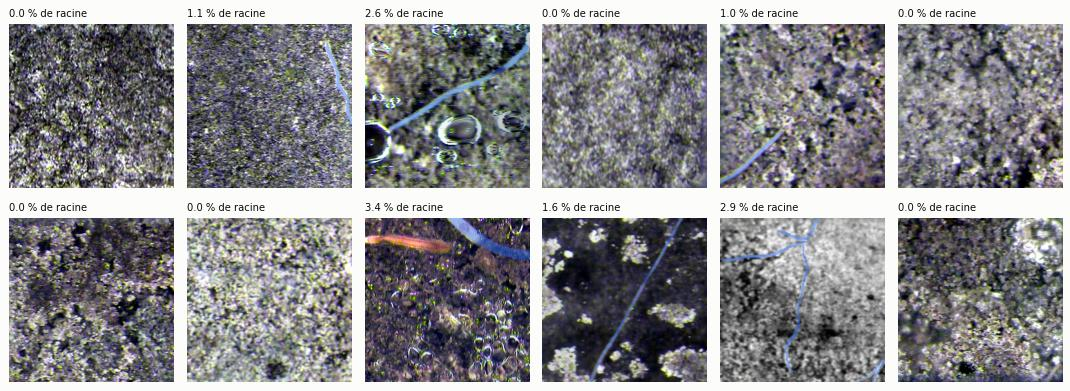

In [2]:
train_items, val_items = load_lot('train', SCALE), load_lot('val', SCALE)
for lot, items in [('train', train_items), ('val', val_items)]:
    print(lot, len(items), 'images, dont', sum(it['mask'].any() for it in items), 'avec racine')

crops = RootCrops(train_items, seed=1, augment=True)
pairs = [crops[i] for i in range(0, 240, 20)]
images = [overlay_mask(to_display(x), y[0].numpy() > 0) for x, y in pairs]
titles = [f'{y.mean() * 100:.1f} % de racine' for _, y in pairs]
viz.image_grid(images, titles, ncols=6);

## 2. Entraînement

Environ 1 h 15 au plus sur le CPU. Une ligne s'affiche à chaque époque ; `history.csv` et `best.pt` sont écrits au fur et à mesure dans `data/processed/runs/`.

Si un entraînement existe déjà sous ce nom, il n'est pas relancé (changer `NAME` pour un nouvel essai). En cas d'arrêt manuel, passer directement à la cellule suivante : elle relit ce qui a été enregistré.

In [3]:
if run_exists(NAME):
    print('Entraînement déjà présent, relecture de', NAME)
else:
    train(train_items, val_items, NAME, augment=True)

cpu, 926,521 paramètres utilisés, 149 images train, 74 images val, 37 batchs par époque
  1/100  perte train 0.512  val 0.260  Dice train 0.512  val 0.490  global 0.603  racines 63%  fantômes 44  longueur 0.28  images vides touchées 0.23  lr 1.0e-04 / 1.0e-03  40 s
  2/100  perte train 0.336  val 0.223  Dice train 0.426  val 0.412  global 0.480  racines 45%  fantômes 10  longueur 0.54  images vides touchées 0.10  lr 1.0e-04 / 1.0e-03  47 s
  3/100  perte train 0.280  val 0.171  Dice train 0.586  val 0.545  global 0.661  racines 66%  fantômes 33  longueur 0.37  images vides touchées 0.23  lr 1.0e-04 / 1.0e-03  68 s
  4/100  perte train 0.252  val 0.150  Dice train 0.647  val 0.602  global 0.684  racines 76%  fantômes 54  longueur 0.26  images vides touchées 0.37  lr 1.0e-04 / 1.0e-03  41 s
  5/100  perte train 0.248  val 0.151  Dice train 0.667  val 0.595  global 0.681  racines 76%  fantômes 72  longueur 0.22  images vides touchées 0.63  lr 1.0e-04 / 1.0e-03  62 s
  6/100  perte train 0

In [4]:
model, history, best_epoch, per_image = load_run(NAME)
device = next(model.parameters()).device
history.tail()

,epoch,lr,lr_encoder,train_loss,train_dice,dice,global_dice,roots_found,ghosts,length_err,fp_empty,val_loss,seconds
95,96,0.000007,0.000002,0.123375,0.813519,0.704671,0.761414,0.838095,36,0.181557,0.366667,0.111142,42.464127
96,97,0.000005,0.000001,0.127511,0.816016,0.705634,0.761910,0.838095,34,0.174579,0.333333,0.110801,49.049351
97,98,0.000003,0.000001,0.133249,0.816790,0.705808,0.762307,0.838095,38,0.161573,0.366667,0.110744,48.410035
98,99,0.000002,0.000001,0.123065,0.816403,0.706476,0.762204,0.838095,39,0.164306,0.366667,0.110558,49.023554
99,100,0.000001,0.000001,0.136957,0.818207,0.704799,0.761671,0.838095,43,0.175795,0.466667,0.110999,49.453642


## 3. Courbes

Pour le surapprentissage, regarder le **Dice** : train et val y sont mesurés de la même façon, sur des images entières (44 images du train avec racine, toujours les mêmes).

La perte train est moyennée sur les carrés de l'époque, la perte val sur les images entières du val, vides comprises : leurs niveaux ne se comparent pas directement, seule leur évolution compte.

,epoch,lr,lr_encoder,train_loss,train_dice,dice,global_dice,roots_found,ghosts,length_err,fp_empty,val_loss,seconds
81,82,0.000087,0.00001,0.122805,0.813879,0.70264,0.76326,0.838095,39,0.150001,0.4,0.111643,45.224611


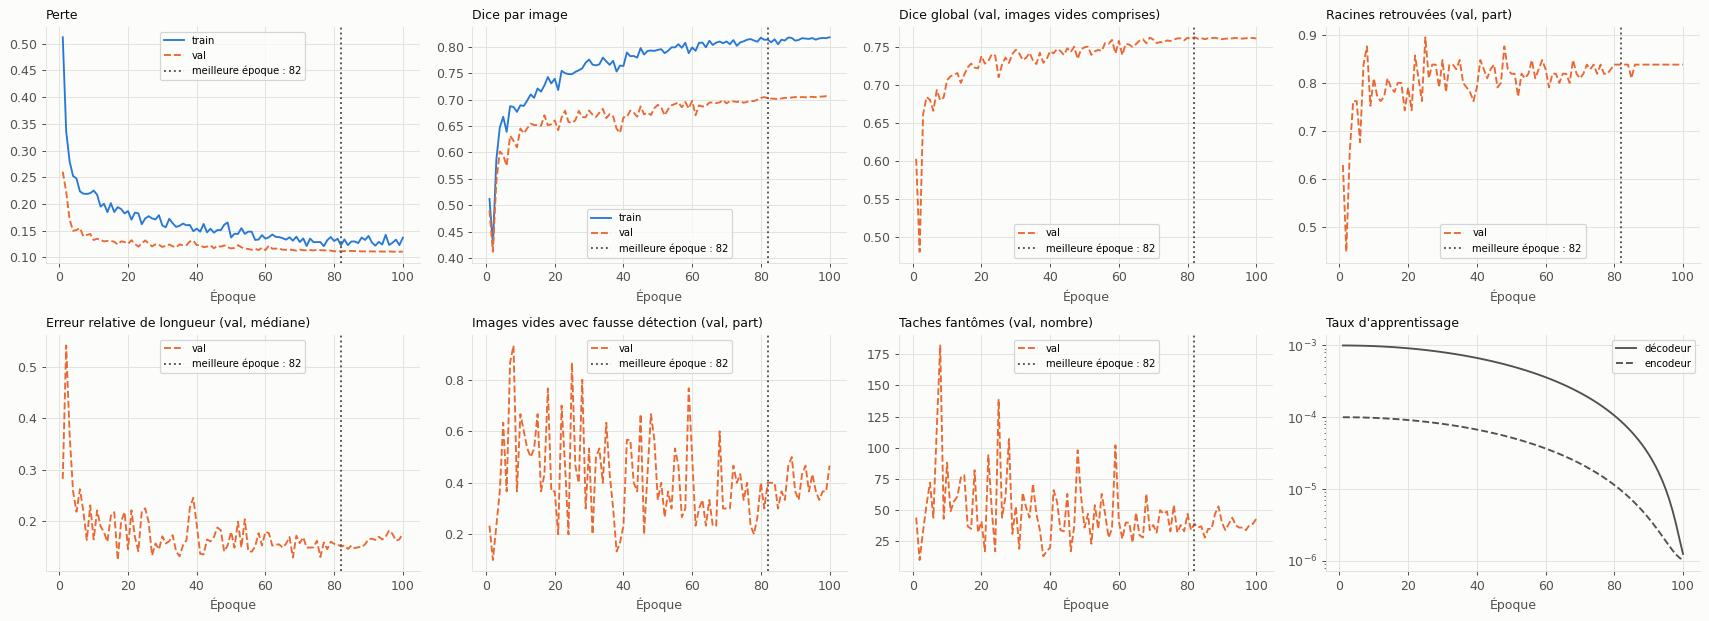

In [5]:
viz.plot_history(history, best_epoch);
history.loc[history['epoch'] == best_epoch]

## 4. Scores du val à la meilleure époque

Le Dice porte sur les images avec racine. Les images vides sont comptées à part. Attention, le val est enrichi en cas difficiles : ces moyennes ne valent pas pour une distribution réelle des images.

Par type
                   dice       length_err      
                 median count     median count
type                                          
faible contraste  0.581     3      0.358     3
grise             0.580     3      0.517     3
orangée           0.733     3      0.126     3
saturée           0.782     4      0.166     4
sombre            0.803     4      0.141     4
typique           0.766    27      0.138    27

Par groupe
               dice       length_err      
             median count     median count
group                                     
150 BAZ 2015  0.766    19      0.156    19
150 BAZ 2016  0.725    15      0.179    15
150 CZ 2016   0.771    10      0.132    10


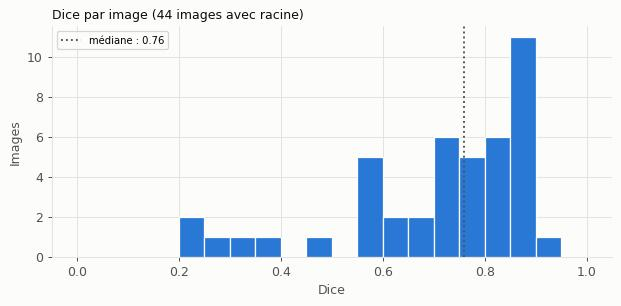

In [6]:
viz.plot_dice(per_image);
rooted = per_image[per_image['has_root']]
print('Par type'); print(rooted.groupby('type')[['dice', 'length_err']].agg(['median', 'count']).round(3))
print('\nPar groupe'); print(rooted.groupby('group')[['dice', 'length_err']].agg(['median', 'count']).round(3))

## 5. Images

Toutes les images du val, au curseur : référence à gauche, prédiction à droite, en résolution de travail. Elles sont triées du plus bas Dice au plus haut, les images sans racine à la fin.

In [7]:
preds = {it['name']: predict(model, it, device) for it in val_items}
viz.browse_predictions(val_items, preds, per_image)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Image', layout=Layout(width='80…

## 6. Ce qu'il faut regarder

- Convergence : les pertes train et val descendent-elles encore à la fin ?
- Surapprentissage : l'écart entre le Dice train et le Dice val se creuse-t-il ?
- Fausses détections : la part d'images vides touchées diminue-t-elle ?
- Longueur : l'erreur suit-elle le Dice, ou le modèle coupe-t-il des racines ?